# Q2: Pandas – Hospital Expenditure Analysis
**Aim:** To analyse patient expenditure across hospital departments using Pandas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("02_Pandas_Hospital_Costs.csv")
except FileNotFoundError:
    np.random.seed(42)
    df = pd.DataFrame({
        "Patient_ID": [f"P{i:03d}" for i in range(1, 51)],
        "Department": np.random.choice(["Cardiology", "Neurology", "Orthopedics", "General", "Pediatrics"], 50),
        "Consultation_Fee_INR": np.random.randint(300, 1500, 50),
        "Diagnostic_Charges_INR": np.random.randint(1000, 9000, 50),
        "Medicine_Charges_INR": np.random.randint(500, 8000, 50)})
    df.loc[df["Department"].isin(["Cardiology", "Neurology"]), "Diagnostic_Charges_INR"] *= 2
    df.loc[5, "Medicine_Charges_INR"] = 40000
df.head()

,Patient_ID,Department,Consultation_Fee_INR,Diagnostic_Charges_INR,Medicine_Charges_INR
0,P001,General,391,7278,7392
1,P002,Pediatrics,1255,1200,2178
2,P003,Orthopedics,808,6959,3742
3,P004,Pediatrics,1075,5875,5136
4,P005,Pediatrics,334,8073,1559


### 1. Dimensions, data types, missing values, duplicates

In [3]:
print("Shape:", df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (50, 5)
Patient_ID                object
Department                object
Consultation_Fee_INR       int64
Diagnostic_Charges_INR     int64
Medicine_Charges_INR       int64
dtype: object
Patient_ID                0
Department                0
Consultation_Fee_INR      0
Diagnostic_Charges_INR    0
Medicine_Charges_INR      0
dtype: int64
Duplicate rows: 0


### 2. Total cost per patient

In [4]:
cols = ["Consultation_Fee_INR", "Diagnostic_Charges_INR", "Medicine_Charges_INR"]
df["Total_Cost_INR"] = df[cols].sum(axis=1)
df.head()

,Patient_ID,Department,Consultation_Fee_INR,Diagnostic_Charges_INR,Medicine_Charges_INR,Total_Cost_INR
0,P001,General,391,7278,7392,15061
1,P002,Pediatrics,1255,1200,2178,4633
2,P003,Orthopedics,808,6959,3742,11509
3,P004,Pediatrics,1075,5875,5136,12086
4,P005,Pediatrics,334,8073,1559,9966


### 3. Department-wise mean, median, SD, variance, CV

In [5]:
dept = df.groupby("Department")["Total_Cost_INR"].agg(["mean", "median", "std", "var"])
dept["CV_%"] = dept["std"] / dept["mean"] * 100
dept.round(2)

,mean,median,std,var,CV_%
Department,,,,,
Cardiology,20015.71,20111.0,5074.11,2.574659e+07,25.35
General,10267.31,9549.0,3221.79,1.037995e+07,31.38
Neurology,18988.40,16738.5,11290.88,1.274839e+08,59.46
Orthopedics,10112.00,10327.0,3658.34,1.338344e+07,36.18
Pediatrics,11153.90,11594.0,3809.19,1.450993e+07,34.15


### 4. Patients above department mean + 1 SD

In [6]:
g = df.groupby("Department")["Total_Cost_INR"]
df[df["Total_Cost_INR"] > g.transform("mean") + g.transform("std")]

,Patient_ID,Department,Consultation_Fee_INR,Diagnostic_Charges_INR,Medicine_Charges_INR,Total_Cost_INR
0,P001,General,391,7278,7392,15061
5,P006,Neurology,505,8208,40000,48713
6,P007,Orthopedics,1404,8215,5779,15398
10,P011,General,1429,6847,6415,14691
19,P020,General,755,7756,6239,14750
30,P031,Orthopedics,679,5488,7892,14059
32,P033,General,1364,6134,5996,13494
35,P036,Pediatrics,364,8035,7276,15675
37,P038,Pediatrics,1452,8858,5568,15878


### 5. Percentage contribution of each charge to total expenditure

In [7]:
(df[cols].sum() / df["Total_Cost_INR"].sum() * 100).round(2)

,0
Consultation_Fee_INR,6.74
Diagnostic_Charges_INR,55.74
Medicine_Charges_INR,37.52


### 6. Departments where diagnostic charges > 55% of total

In [8]:
share = df.groupby("Department")[cols].sum()
share = share.div(share.sum(axis=1), axis=0) * 100
print(share.round(2))
share[share["Diagnostic_Charges_INR"] > 55].round(2)

             Consultation_Fee_INR  Diagnostic_Charges_INR  \
Department                                                  
Cardiology                   4.94                   72.04   
General                      9.41                   49.57   
Neurology                    3.91                   50.75   
Orthopedics                 10.03                   51.56   
Pediatrics                   7.64                   54.96   

             Medicine_Charges_INR  
Department                         
Cardiology                  23.02  
General                     41.02  
Neurology                   45.34  
Orthopedics                 38.41  
Pediatrics                  37.39  


,Consultation_Fee_INR,Diagnostic_Charges_INR,Medicine_Charges_INR
Department,,,
Cardiology,4.94,72.04,23.02


### 7. groupby(), agg(), transform(), rank()

In [9]:
df.groupby("Department").agg(Patients=("Patient_ID", "count"),
                             Avg_Total=("Total_Cost_INR", "mean"),
                             Max_Total=("Total_Cost_INR", "max")).round(2)

,Patients,Avg_Total,Max_Total
Department,,,
Cardiology,7,20015.71,24795
General,13,10267.31,15061
Neurology,10,18988.40,48713
Orthopedics,10,10112.00,15398
Pediatrics,10,11153.90,15878


In [10]:
df["Dept_Avg"] = g.transform("mean").round(2)
df["Rank_in_Dept"] = g.rank(ascending=False, method="min")
df.sort_values(["Department", "Rank_in_Dept"])[["Patient_ID", "Department", "Total_Cost_INR", "Dept_Avg", "Rank_in_Dept"]]

,Patient_ID,Department,Total_Cost_INR,Dept_Avg,Rank_in_Dept
38,P039,Cardiology,24795,20015.71,1.0
18,P019,Cardiology,24574,20015.71,2.0
41,P042,Cardiology,23783,20015.71,3.0
24,P025,Cardiology,20111,20015.71,4.0
45,P046,Cardiology,18964,20015.71,5.0
33,P034,Cardiology,17240,20015.71,6.0
23,P024,Cardiology,10643,20015.71,7.0
0,P001,General,15061,10267.31,1.0
19,P020,General,14750,10267.31,2.0
10,P011,General,14691,10267.31,3.0


### 8. IQR outliers per department

In [11]:
q1 = g.transform(lambda s: s.quantile(0.25))
q3 = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["Outlier"] = (df["Total_Cost_INR"] < q1 - 1.5 * iqr) | (df["Total_Cost_INR"] > q3 + 1.5 * iqr)
df[df["Outlier"]]

,Patient_ID,Department,Consultation_Fee_INR,Diagnostic_Charges_INR,Medicine_Charges_INR,Total_Cost_INR,Dept_Avg,Rank_in_Dept,Outlier
5,P006,Neurology,505,8208,40000,48713,18988.4,1.0,True
39,P040,Neurology,1386,3726,1782,6894,18988.4,10.0,True


### 9. Multi-index summary, grouped bar chart, boxplot

In [12]:
summary = df.groupby("Department")[cols].agg(["sum", "mean"]).round(0)
summary

Consultation_Fee_INR         Diagnostic_Charges_INR           \
                             sum    mean                    sum     mean   
Department                                                                 
Cardiology                  6927   990.0                 100930  14419.0   
General                    12560   966.0                  66157   5089.0   
Neurology                   7429   743.0                  96366   9637.0   
Orthopedics                10140  1014.0                  52135   5214.0   
Pediatrics                  8527   853.0                  61302   6130.0   

            Medicine_Charges_INR          
                             sum    mean  
Department                                
Cardiology                 32253  4608.0  
General                    54758  4212.0  
Neurology                  86089  8609.0  
Orthopedics                38845  3884.0  
Pediatrics                 41710  4171.0

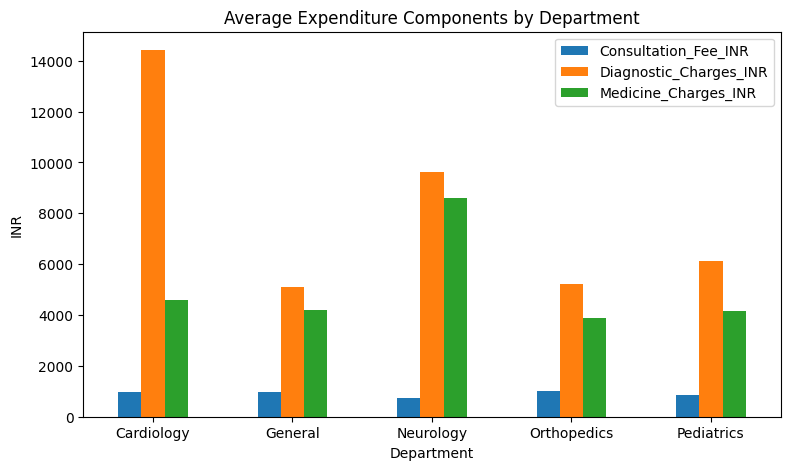

In [13]:
df.groupby("Department")[cols].mean().plot(kind="bar", figsize=(9, 5))
plt.title("Average Expenditure Components by Department")
plt.ylabel("INR")
plt.xticks(rotation=0)
plt.show()

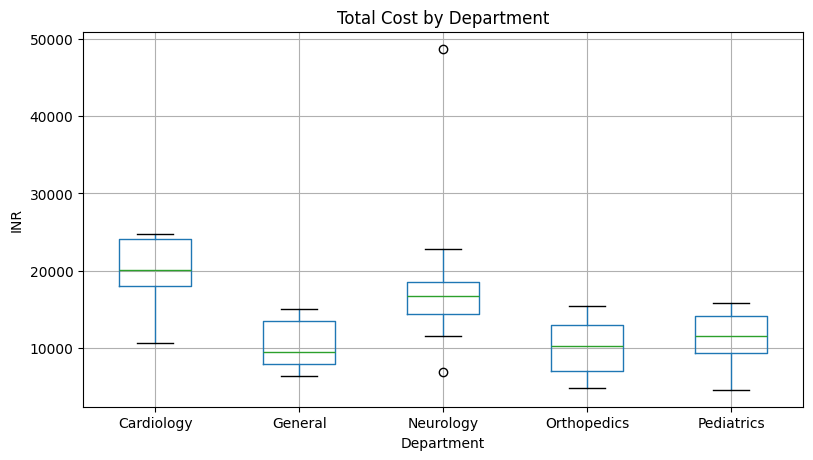

In [14]:
df.boxplot(column="Total_Cost_INR", by="Department", figsize=(9, 5))
plt.suptitle("")
plt.title("Total Cost by Department")
plt.ylabel("INR")
plt.show()

**Result:** Department-wise hospital expenditure was analysed successfully using Pandas groupby, agg, transform and rank, with outliers and visual summaries.